### Theoretical Primer

Given a set of data points $\bm{x}_1, \bm{x}_2, ..., \bm{x}_n$ in $d$-dimensional metric space, the optimal partitioning of this space into $k$ subsets $\bm{S} = \{S_1, S_2, ..., S_k\}$ is obtained by minimizing the variance within each of the subsets. That is:

$\displaystyle \bm{S}^* = \arg \min_S \sum_{i = 1}^k \sum_{\bm{x} \in S_i} || \bm{x} - \bm{\mu}_i ||^2 = \arg \min_S |S_i| ~ Var S_i $.

### K - means clustering algorithm:

Given a set of data points $\bm{x}_1, \bm{x}_2, ..., \bm{x}_n$, we aim to minimize the function above. This is done as follows:

- Input: Data points $(\bm{x}_1, \bm{x}_2, ..., \bm{x}_n)$ and number of cluster $k$
- Output: Optimal partition sets $\bm{S}^* = \{S_1, S_2, ..., S_k\}$
1. <b>Initialize</b> cluster centers $\bm{\mu}_j^{(1)}, j = 1..k$ to random values
2. <b>REPEAT</b>:

   1. <b>Assignment step</b>:
      Assign each data point $\bm{x}_i, i = 1..n$ to the closest cluster. This produces partition sets:
   
      $\displaystyle S_m^{(t)} = \left\lbrace \bm{x}_p \quad | \quad || \bm{x}_p - \bm{\mu}_m ||^2 \leq || \bm{x}_p - \bm{\mu}_n ||^2, \quad \forall n=1..k \text{ and } m = 1..k \right\rbrace$

   2. <b>Update step</b>:
      Update the cluster centers (means of each partition set) to new values:

      $\displaystyle \bm{\mu}_i^{(t+1)} = \dfrac{1}{|S_i^{(t)}|} \sum_{\bm{x}_l \in S_i^{(t)} } x_l $

3. <b>UNTIL</b> convergence is reached:

   $\displaystyle || \bm{\mu}^{(t+1)} - \bm{\mu}^{(t)} || < \text{EPS} $

   




In [5]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial import Voronoi, voronoi_plot_2d

In [6]:
def plot_kmeans(X, mu, S, iteration, k, initial=False):
    plt.figure(figsize=(8, 5))

    if initial:
        plt.scatter(X[:, 0], X[:, 1], marker='o', edgecolor='k', s=50, alpha=0.6, label='Data points')
    else:
        plt.scatter(X[:, 0], X[:, 1], c=S, cmap='tab20', marker='o', edgecolor='k', s=50, alpha=0.6, label='Data points')

    plt.scatter(mu[:, 0], mu[:, 1], c='red', marker='x', s=300, label='Centroids')

    if not initial:
        vor = Voronoi(mu)
        voronoi_plot_2d(vor, ax=plt.gca(), show_vertices=True, line_colors='blue', line_width=2, line_alpha=0.6, point_size=2)

    x_low, x_high = np.min(X[:, 0]) - 0.1, np.max(X[:, 0]) + 0.1
    y_low, y_high = np.min(X[:, 1]) - 0.1, np.max(X[:, 1]) + 0.1

    if initial:
        plt.title(f"K-Means Clustering - Initialization")
    else:
        plt.title(f"K-Means Clustering - Iteration {iteration+1}")
    plt.xlabel('Feature 1')
    plt.ylabel('Feature 2')
    plt.legend()
    plt.xlim([x_low, x_high])
    plt.ylim([y_low, y_high])
    plt.show()

In [7]:
def kmeans(X, k, max_iters=10):
    np.random.seed(42)
    mu_t = X[np.random.choice(X.shape[0], k, replace=False)]
    for iter in range(max_iters):
        # Step 1: Assign clusters
        d = np.linalg.norm(X[:, np.newaxis] - mu_t, axis=2)

        S_t = np.argmin(d, axis=1)

        # Step 2: Update centroids
        mu_t1 = np.array([X[S_t == i].mean(axis=0) for i in range(k)])

        if iter == 0:
            plot_kmeans(X, mu_t, S_t, iter, k, True)
        plot_kmeans(X, mu_t, S_t, iter, k)

        # Check if the algorithm is converged
        EPS = 1e-6
        if np.linalg.norm(mu_t1 - mu_t) < EPS:
            print("Convergence reached")
            break

        mu_t = mu_t1

    return mu_t, S_t

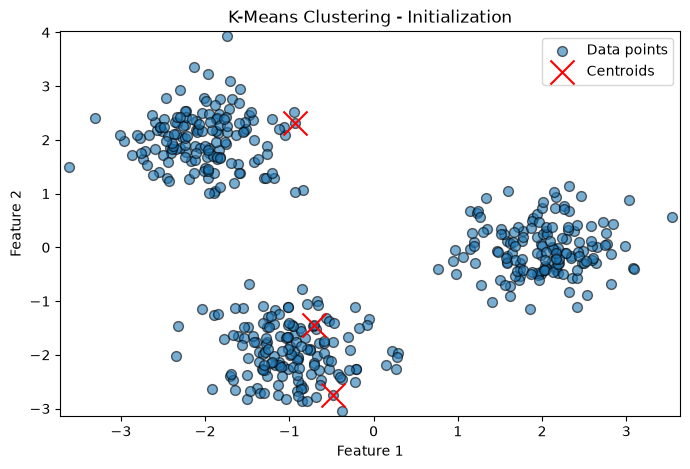

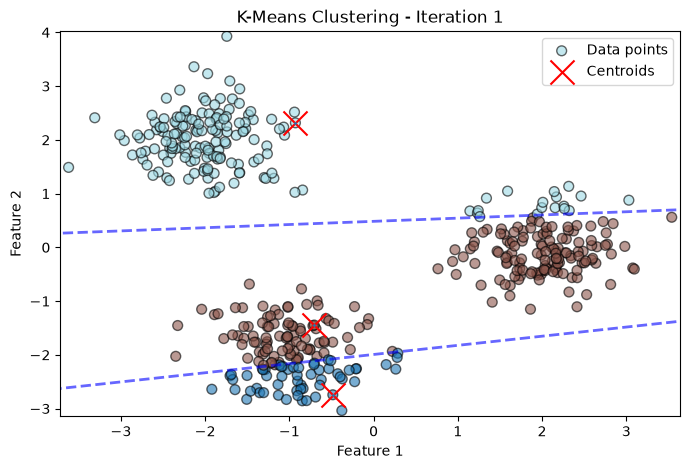

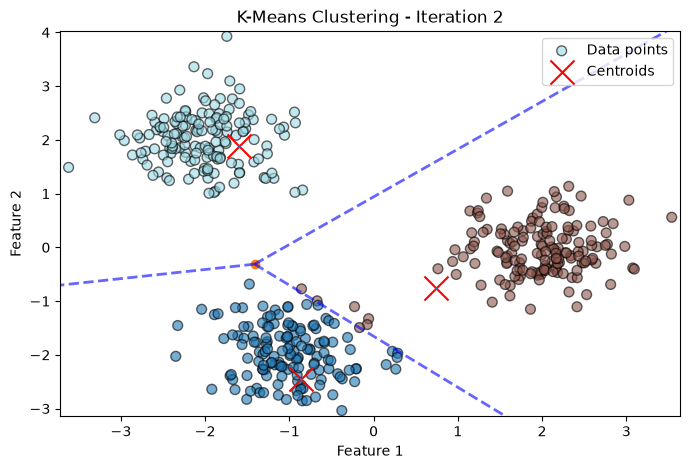

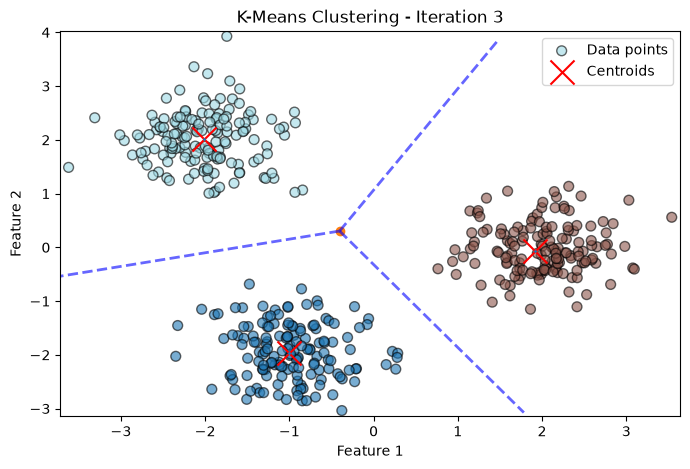

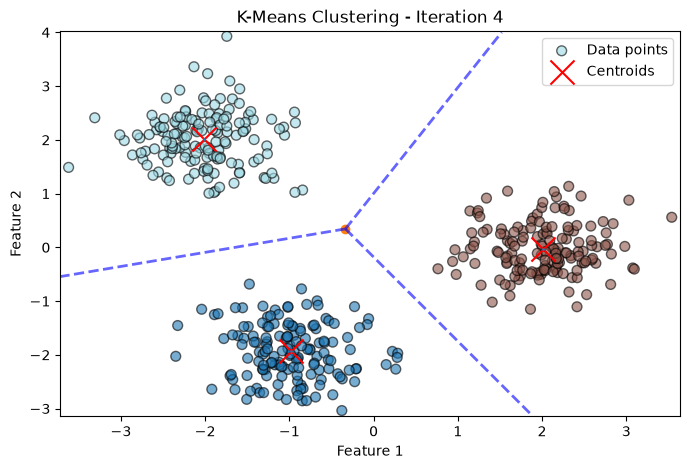

Convergence reached


In [8]:
np.random.seed(42)
X = np.vstack((
    np.random.randn(150, 2) * 0.5 + np.array([-2, 2]),
    np.random.randn(150, 2) * 0.5 + np.array([2, 0]),
    np.random.randn(150, 2) * 0.5 + np.array([-1, -2])
))

# Number of clusters
k = 3

# Run K-Means
mu, S = kmeans(X, k)